# 11 · A3 stage 2: AETHER's recipe on US farm country, with NASA POWER and OpenStreetMap (U1, C1)

Settings fixed in `PLAN.md` (A3, A3.1, A3.2) and `configs/aether_us.yaml` before this notebook ran.

- **Location** = one 30 m pixel: AlphaEarth (64) plus the POWER summary vector of its cell (907), standardised.
- **Model** = AETHER's MLP projector (3 layers, 512 wide) into a frozen text space; **loss** = their soft
  contrastive loss (our port, checked in notebook 09), sigma 0.1, learnable temperature.
- **Captions** = A2's generator (land, distance, patch, climate facts) plus OpenStreetMap tags (notebook 10).
- **Text encoders**: their frozen CLIP ViT-L-14 text tower, and (C1) Qwen3-Embedding-0.6B.
- **U1 (a)**: their concept-retrieval index in the held-out states (Minnesota, Georgia), mean over fact groups.
  **U1 (b)**: persona questions, AP − chance. **C1**: the U1 (a) difference between the two text encoders.

In [1]:
import json
import time

import numpy as np
import pandas as pd

from askmap.catalogue import area_classes
from askmap.config import PROJECT_ROOT, data_root, load_config
from askmap.layers import SOLAR_LATER, official_leaf_map
from askmap.plan import AreaContext, execute
from askmap.power import add_derived, fetch_daily, pixel_cells
from askmap.tiles import area_tiles, pixel_lonlat
from askmap.universe import Universe, box_of

cfg = load_config(PROJECT_ROOT / "configs" / "feasibility.yaml")
Q = load_config(PROJECT_ROOT / "configs" / "queries.yaml")["queries"]
RW = load_config(PROJECT_ROOT / "configs" / "reworded.yaml")["reworded"]
ROOT = data_root()
RES = PROJECT_ROOT / "outputs" / "results"
FIG = PROJECT_ROOT / "outputs" / "figures"
CL, P, SC = cfg["classes"], cfg["power"], cfg["scoring"]
LEAVES, GROUPS = CL["leaves"], CL["groups"]
CATALOGUE = area_classes(cfg)
T_START = time.time()
cells = pd.read_parquet(ROOT / "power" / "universe_cells.parquet")
daily = {
    box: add_derived(fetch_daily(P, b, ROOT / "power" / f"universe_{box}_daily.nc"), P["low_wind_sun_pct"])
    for box, b in P["boxes"].items()
}
uni = Universe(cells=cells, daily=daily)
SEEN = ["north_dakota", "north_carolina"]
HELD = cfg["heldout_pools"]  # seen area -> held-out state
POOL_Q = {
    "north_dakota": "north_dakota",
    "north_carolina": "north_carolina",
    "minnesota": "north_dakota",
    "georgia": "north_carolina",
}  # pool -> area whose questions it answers
T = {}
for area in POOL_Q:
    for name, (tile, role) in area_tiles(cfg["areas"][area], cfg["grid"]).items():
        z = np.load(ROOT / "tiles" / f"{area}_{name}.npz")
        solar = z["solar"] if "solar" in z.files else None
        nwi = z["nwi"] if "nwi" in z.files else None
        valid = np.isfinite(z["ae"]).all(axis=0)
        if solar is not None:
            valid &= solar != SOLAR_LATER
        lon, lat = pixel_lonlat(tile)
        box = box_of(float(lon.mean()), float(lat.mean()), P["boxes"])
        iy, ix = pixel_cells(daily[box].lat.values, daily[box].lon.values, lat, lon)
        T[name] = {
            "area": area,
            "role": role,
            "valid": valid,
            "box": box,
            "iy": iy,
            "ix": ix,
            "cell": uni.index(box, iy, ix),
            "official": official_leaf_map(z["cdl"], LEAVES, CL, nwi=nwi, solar=solar),
        }
        if role == "test":
            T[name]["ae_map"] = np.load(ROOT / "maps" / f"ae_{name}.npz")["leaf"]
            T[name]["planted_map"] = np.load(ROOT / "maps" / f"planted_{name}.npz")["leaf"]
CTX, TILES = {}, {}
for area in POOL_Q:
    names = [n for n, t in T.items() if t["area"] == area]
    ds = daily[T[names[0]]["box"]]
    ac = np.zeros((ds.sizes["lat"], ds.sizes["lon"]), bool)
    for n in names:
        ac[T[n]["iy"], T[n]["ix"]] = True
    CTX[area] = AreaContext(
        leaves=LEAVES,
        groups=GROUPS,
        res_m=cfg["grid"]["res_m"],
        power=ds,
        area_cells=ac,
        pixel_cell={n: (T[n]["iy"], T[n]["ix"]) for n in names},
    )
    TILES[area] = {
        "train": [n for n in names if T[n]["role"] == "train"],
        "test": [n for n in names if T[n]["role"] == "test"],
    }


def answer(plan, pool, maps="official"):
    """Answer of a plan in a pool's test tiles, as one vector over their valid pixels (fixed tile order)."""
    tiles = TILES[pool]["test"]
    key = "official" if maps == "official" else f"{maps}_map"
    got = execute(plan, {n: T[n][key] for n in tiles}, CTX[pool])
    return np.concatenate([got[n][T[n]["valid"]] for n in tiles])


def question_text(q, wording, pool):
    text = q["question"] if wording != "reworded" else RW[q["id"]]
    if pool in ("minnesota", "georgia"):
        text = text.replace("North Dakota", "Minnesota").replace("North Carolina", "Georgia")
    return text


def n_extra(plan):
    return len(plan["near"]) + len(plan["climate"]) + int(plan["land"]["min_patch_ha"] is not None)


print(f"{len(T)} tiles loaded; pools {dict((a, TILES[a]['test']) for a in POOL_Q)}")

18 tiles loaded; pools {'north_dakota': ['Kidder', 'Foster', 'Eddy'], 'north_carolina': ['NC4', 'NC5', 'NC6'], 'minnesota': ['MN1', 'MN2', 'MN3'], 'georgia': ['GA1', 'GA2', 'GA3']}


In [2]:
import os

import matplotlib.pyplot as plt
import torch
from sklearn.metrics import average_precision_score

from askmap.aether_us import (
    Bank,
    TileScores,
    captions_for,
    climate_only_spec,
    concept_indices,
    group_mean,
    multiset_index,
    project,
    similarities,
    text_vectors,
    train,
)
from askmap.captions import Location, Vocab, fact_text, near_text
from askmap.layers import class_mask
from askmap.local_facts import distances, leaf_patch_ha, patch_area_ha, sample_pixels
from askmap.space import Items, specs_from

AU = load_config(PROJECT_ROOT / "configs" / "aether_us.yaml")
CAP = load_config(PROJECT_ROOT / "configs" / "captions.yaml")
SM, MCFG, CC, ACAP = cfg["sampling"], AU["model"], AU["concepts"], AU["captions"]
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
f = np.load(ROOT / "climate" / "facts.npz")
FACT_IDS, TABLE = [str(x) for x in f["ids"]], f["table"]
FAMILY = np.array(["long" if i.split("|")[0] == "sun" else i.split("|")[0] for i in FACT_IDS])
SUMMARY = np.load(ROOT / "climate" / "enc_summary.npy")
vocab = Vocab(CAP, LEAVES, GROUPS, FACT_IDS)
NEAR = vocab.near_classes
OTHER = LEAVES.index("other")
RES_M = cfg["grid"]["res_m"]
NPX = round(cfg["grid"]["tile_size_m"] / RES_M)
OV = AU["osm"]["vocab"]
USED = pd.read_csv(RES / "10_osm_used.csv").entry.tolist()
WORDS = [OV[k]["words"] for k in USED]
OUT = ROOT / "aether_us"
OUT.mkdir(exist_ok=True)
HF_CACHE = os.environ["HF_HOME"]
print(f"device {device}; {len(USED)} OpenStreetMap entries used; {len(FACT_IDS)} climate facts")


def osm_layers(area, name):
    z = np.load(ROOT / "osm" / f"{area}_{name}.npz")
    return np.stack([np.unpackbits(z[k])[: NPX * NPX].reshape(NPX, NPX) for k in USED]).astype(bool)


def local(leaf):
    return {
        "dist": distances(leaf, NEAR, LEAVES, GROUPS, RES_M),
        "patch_leaf": leaf_patch_ha(leaf, len(LEAVES), RES_M),
        "patch_crop": patch_area_ha(class_mask(leaf, "cropland", LEAVES, GROUPS), RES_M),
    }

device mps; 23 OpenStreetMap entries used; 4006 climate facts


## Training locations (A2's sample: 5,000 pixels per training tile) with OpenStreetMap tags

In [3]:
parts = []
for k, (area, acfg) in enumerate(cfg["areas"].items()):
    for j, (name, (tile, role)) in enumerate(area_tiles(acfg, cfg["grid"]).items()):
        if role != "train":
            continue
        z = np.load(ROOT / "tiles" / f"{area}_{name}.npz")
        solar = z["solar"] if "solar" in z.files else None
        nwi = z["nwi"] if "nwi" in z.files else None
        leaf = official_leaf_map(z["cdl"], LEAVES, CL, nwi=nwi, solar=solar)
        valid = np.isfinite(z["ae"]).all(axis=0) & (leaf != OTHER)
        if solar is not None:
            valid &= solar != SOLAR_LATER
        lon, lat = pixel_lonlat(tile)
        box = box_of(float(lon.mean()), float(lat.mean()), P["boxes"])
        iy, ix = pixel_cells(daily[box].lat.values, daily[box].lon.values, lat, lon)
        cell = uni.index(box, iy, ix)
        lf = local(leaf)
        flat = sample_pixels(leaf, valid, SM["train_pixels_per_tile"], len(LEAVES), SM["seed"] + 100 * k + j)
        parts.append(
            {
                "ae": z["ae"].reshape(64, -1)[:, flat].T.astype(np.float32),
                "leaf": leaf.ravel()[flat],
                "dist": lf["dist"].reshape(-1, len(NEAR))[flat],
                "patch_leaf": lf["patch_leaf"].ravel()[flat],
                "patch_crop": lf["patch_crop"].ravel()[flat],
                "cell": cell.ravel()[flat],
                "osm": osm_layers(area, name).reshape(len(USED), -1)[:, flat].T,
                "area": np.full(len(flat), area),
            }
        )
LOC = {key: np.concatenate([p[key] for p in parts]) for key in parts[0]}
assert not cells.heldout.to_numpy()[LOC["cell"]].any()
N = len(LOC["leaf"])
XRAW = np.c_[LOC["ae"], SUMMARY[LOC["cell"]]]
MU, SD = XRAW.mean(0), XRAW.std(0)
SD[SD == 0] = 1.0


def standardise(ae, cell):
    return ((np.c_[ae, SUMMARY[cell]] - MU) / SD).astype(np.float32)


X = standardise(LOC["ae"], LOC["cell"])
print(
    f"{N:,} training locations; {X.shape[1]} inputs; share with any OpenStreetMap tag "
    f"{LOC['osm'].any(axis=1).mean():.2f}"
)

85,000 training locations; 971 inputs; share with any OpenStreetMap tag 0.17


## Captions (A2's generator + OpenStreetMap) and climate-only captions attached to a location of their cell

In [4]:
rng = np.random.default_rng(ACAP["seed"])
cache = {}


def true_facts(c):
    if c not in cache:
        on = np.flatnonzero(TABLE[c])
        cache[c] = {fam: on[FAMILY[on] == fam] for fam in ("hist", "heat", "rain", "gdd", "long")}
    return cache[c]


locs = [
    Location(
        int(LOC["leaf"][j]),
        LOC["dist"][j],
        float(LOC["patch_leaf"][j]),
        float(LOC["patch_crop"][j]),
        true_facts(int(LOC["cell"][j])),
        str(LOC["area"][j]),
    )
    for j in range(N)
]
rows = captions_for(locs, LOC["osm"], vocab, WORDS, AU["osm"]["join"], ACAP, rng)
comp = CAP["composition"]
fams = ["hist", "heat", "rain", "gdd", "long"]
fam_p = np.array([comp["climate_year"] / 4] * 4 + [comp["climate_long"]])
members = pd.Series(np.arange(N)).groupby(LOC["cell"]).apply(np.array)
for c, mem in members.items():
    tf = true_facts(int(c))
    for _ in range(ACAP["climate_only_per_cell"]):
        order = [fm for fm in rng.choice(fams, size=5, replace=False, p=fam_p / fam_p.sum()) if len(tf[fm])]
        fid = int(rng.choice(tf[order[0]]))
        rows.append(
            {
                "item": int(rng.choice(mem)),
                "osm": -1,
                "text": str(rng.choice(CAP["prefixes"]))
                + fact_text(FACT_IDS[fid], CAP, int(rng.integers(3))),
                "spec": climate_only_spec(len(LEAVES), len(NEAR), fid),
            }
        )
caps = pd.DataFrame(rows)
print(f"{len(caps):,} captions ({(caps.osm >= 0).mean():.2%} with an OpenStreetMap fact)")
caps.text.sample(12, random_state=0).tolist()

510,930 captions (5.92% with an OpenStreetMap fact)


['Places with minor annual crops where May-September 2022 had at most 1400 growing degree days (base 10 C)',
 'Show towns or other annual crops where average sunlight over 2001-2025 is at least 4.4 kWh per square metre per day in Nebraska',
 'Find grassland',
 'Places with woodland among the half of places with the highest cooling demand (2001-2025 average) in Virginia',
 'Find built-up land with average temperature in July and August 2007 among the hottest 10% of 2001-2025',
 'wetland areas with 10 or more days over 30 C in the month of July 2023 in the Virginia study area',
 'Places with roads and farmsteads in the highest third of places by heating degree days over 2001-2025',
 'Find lakes and ponds in the most half of the region for calm, dark days, 2001-2025',
 'towns',
 'hayfields more than 1 km from any an existing solar farm, tagged as farm fields',
 'Show roads, farmyards and scattered houses that got at least 250 mm of rain in April to June 2002',
 'Places with crop fields or

## Concepts for their index (one caption each, wording 0)

In [5]:
def fact_year(fid):
    p = fid.split("|")
    return {
        "hist": p[3] if len(p) > 3 else None,
        "heat": p[3] if len(p) > 3 else None,
        "rain": p[2] if len(p) > 2 else None,
        "gdd": p[1] if len(p) > 1 else None,
    }.get(p[0])


CONCEPTS = [
    {"group": "land", "name": n, "text": CAP["land"][n][0], "kind": "land", "arg": n}
    for n in [x for x in LEAVES if x != "other"] + list(GROUPS)
]
CONCEPTS += [
    {"group": "osm", "name": k, "text": OV[k]["words"][0], "kind": "osm", "arg": i}
    for i, k in enumerate(USED)
]
CONCEPTS += [
    {
        "group": "distance",
        "name": f"near_{c}_{d}",
        "text": near_text([c], d, False, CAP, 0),
        "kind": "near",
        "arg": (NEAR.index(c), d),
    }
    for c in CC["near_classes"]
    for d in CC["near_distances_m"]
]
CONCEPTS += [
    {"group": "climate", "name": fid, "text": fact_text(fid, CAP, 0), "kind": "fact", "arg": i}
    for i, fid in enumerate(FACT_IDS)
    if fid.split("|")[0] in ("long", "sun") or fact_year(fid) == str(CC["climate_year"])
]
CGROUP = np.array([c["group"] for c in CONCEPTS])


def concept_truth(leaf, dist, osm, cell):
    out = np.zeros((len(CONCEPTS), len(leaf)), dtype=bool)
    for i, cn in enumerate(CONCEPTS):
        if cn["kind"] == "land":
            out[i] = np.isin(leaf, vocab.leaf_set(cn["arg"]))
        elif cn["kind"] == "osm":
            out[i] = osm[:, cn["arg"]]
        elif cn["kind"] == "near":
            out[i] = dist[:, cn["arg"][0]] <= cn["arg"][1]
        else:
            out[i] = TABLE[cell, cn["arg"]]
    return out


pd.Series(CGROUP).value_counts()

climate     190
osm          23
land         18
distance     12
Name: count, dtype: int64

## Scored pixels: every valid pixel of each pool's test tiles

In [6]:
POOLS = {}
for pool in POOL_Q:
    keep = {k: [] for k in ("ae", "leaf", "dist", "osm", "cell", "tile")}
    for ti, n in enumerate(TILES[pool]["test"]):
        flat = np.flatnonzero(T[n]["valid"].ravel())
        z = np.load(ROOT / "tiles" / f"{T[n]['area']}_{n}.npz")["ae"]
        keep["ae"].append(z.reshape(64, -1)[:, flat].T.astype(np.float16))
        keep["leaf"].append(T[n]["official"].ravel()[flat])
        keep["dist"].append(local(T[n]["official"])["dist"].reshape(-1, len(NEAR))[flat])
        keep["osm"].append(osm_layers(T[n]["area"], n).reshape(len(USED), -1)[:, flat].T)
        keep["cell"].append(T[n]["cell"].ravel()[flat])
        keep["tile"].append(np.full(len(flat), ti))
    POOLS[pool] = {k: np.concatenate(v) for k, v in keep.items()}
TRUTH = dict(np.load(ROOT / "maps" / "truth.npz"))
QROWS = []
for q in Q:
    seen = q["plan"]["area"]
    for wording, pool in (("as_written", seen), ("reworded", seen), ("as_written", HELD[seen])):
        n = len(POOLS[pool]["cell"])
        g = np.unpackbits(TRUTH[f"{q['id']}|{pool}"])[:n].astype(bool)
        QROWS.append(
            {
                "id": q["id"],
                "wording": wording,
                "pool": pool,
                "text": question_text(q, wording, pool),
                "truth": g,
                "persona": q["persona"],
                "has_climate": bool(q["plan"]["climate"]),
            }
        )
print({p: len(v["cell"]) for p, v in POOLS.items()}, f"{len(QROWS)} question-pool rows")

{'north_dakota': 1334667, 'north_carolina': 1334667, 'minnesota': 1334647, 'georgia': 1334667} 174 question-pool rows


## Validation split and training material

In [7]:
vr = np.random.default_rng(MCFG["seed"])
perm = vr.permutation(N)
n_val = int(MCFG["val_share"] * N)
VAL, TRN = np.sort(perm[:n_val]), np.sort(perm[n_val:])
VAL_TRUTH = concept_truth(LOC["leaf"][VAL], LOC["dist"][VAL], LOC["osm"][VAL], LOC["cell"][VAL])
STRINGS = pd.unique(
    pd.concat(
        [caps.text, pd.Series([c["text"] for c in CONCEPTS]), pd.Series([r["text"] for r in QROWS])]
    ).to_numpy()
)
POS = {s: i for i, s in enumerate(STRINGS)}
t_ = torch.as_tensor
ITEMS = Items(
    t_(LOC["leaf"], dtype=torch.long, device=device),
    t_(LOC["dist"], dtype=torch.float32, device=device),
    t_(LOC["patch_leaf"], dtype=torch.float32, device=device),
    t_(LOC["patch_crop"], dtype=torch.float32, device=device),
    t_(LOC["cell"], dtype=torch.long, device=device),
)
SPECS = specs_from(caps.spec.tolist(), device)
print(f"{len(TRN):,} training / {len(VAL):,} validation locations; {len(STRINGS):,} distinct texts")

76,500 training / 8,500 validation locations; 296,547 distinct texts


## Train and score, once per text encoder

In [8]:
ENCODERS = {
    "clip": ("clip", AU["text_encoders"]["clip"]),
    "modern": ("sentence_transformer", AU["text_encoders"]["modern"]),
}
HELDOUT = ["minnesota", "georgia"]
br = np.random.default_rng(CC["seed"])
NT = {pool: int(POOLS[pool]["tile"].max()) + 1 for pool in HELDOUT}
DRAWS = [
    {pool: np.bincount(br.integers(0, NT[pool], NT[pool]), minlength=NT[pool]) for pool in HELDOUT}
    for _ in range(CC["bootstrap"])
]
RESULTS, HIST = {}, {}
for enc_name, (kind, model_name) in ENCODERS.items():
    t0 = time.time()
    E = text_vectors(list(STRINGS), model_name, kind, device, HF_CACHE)
    t_enc = time.time() - t0
    En = E / np.linalg.norm(E, axis=1, keepdims=True)
    bank = Bank(
        x=t_(X, device=device),
        items=ITEMS,
        osm=t_(LOC["osm"], device=device),
        cell_facts=t_(TABLE, device=device),
        cap_item=t_(caps.item.to_numpy(), dtype=torch.long, device=device),
        cap_text=t_(E[caps.text.map(POS).to_numpy()], device=device),
        specs=SPECS,
        cap_osm=t_(caps.osm.to_numpy(), dtype=torch.long, device=device),
    )
    CV = En[[POS[c["text"]] for c in CONCEPTS]]

    def val_eval(model, CV=CV):
        z = project(model, X[VAL], device)
        idx = concept_indices(CV @ z.T, VAL_TRUTH, CC["min_positive_px"], CC["max_positive_share"])
        return group_mean(idx, CGROUP)

    model, log_temp, hist = train(bank, TRN, VAL, val_eval, MCFG, device)
    torch.save(
        {"state": model.state_dict(), "log_temp": log_temp, "mu": MU, "sd": SD, "encoder": model_name},
        OUT / f"projector_{enc_name}.pt",
    )
    np.savez_compressed(
        OUT / f"text_{enc_name}.npz", strings=STRINGS.astype(str), vectors=E.astype(np.float16)
    )
    HIST[enc_name] = pd.DataFrame(hist)
    per_pool = {}
    for pool, pdata in POOLS.items():
        qs = [r for r in QROWS if r["pool"] == pool]
        QV = En[[POS[r["text"]] for r in qs]]
        both = similarities(
            model, pdata["ae"].astype(np.float32), pdata["cell"], SUMMARY, MU, SD, np.r_[CV, QV], device
        )
        sim, qsim = both[: len(CV)], both[len(CV) :]
        truth_cn = concept_truth(pdata["leaf"], pdata["dist"], pdata["osm"], pdata["cell"])
        idx = concept_indices(sim, truth_cn, CC["min_positive_px"], CC["max_positive_share"])
        boot = None
        if pool in HELDOUT:
            ts = [TileScores.of(sim[c], truth_cn[c], pdata["tile"], NT[pool]) for c in range(len(CONCEPTS))]
            boot = np.array(
                [
                    group_mean(
                        np.array(
                            [
                                multiset_index(t, d[pool], CC["min_positive_px"], CC["max_positive_share"])
                                for t in ts
                            ]
                        ),
                        CGROUP,
                    )
                    for d in DRAWS
                ]
            )
            del ts
        qres = [
            {
                "id": r["id"],
                "wording": r["wording"],
                "pool": pool,
                "has_climate": r["has_climate"],
                "truth_px": int(r["truth"].sum()),
                "prevalence": float(r["truth"].mean()),
                "AP": average_precision_score(r["truth"], s) if r["truth"].any() else np.nan,
                "F1_topk": float(
                    r["truth"][np.argpartition(-s, int(r["truth"].sum()))[: int(r["truth"].sum())]].mean()
                )
                if r["truth"].any()
                else np.nan,
            }
            for r, s in zip(qs, qsim, strict=True)
        ]
        per_pool[pool] = {"index": idx, "boot": boot, "questions": pd.DataFrame(qres)}
        del both, sim, qsim, truth_cn
    RESULTS[enc_name] = per_pool
    print(
        f"{enc_name}: encode {t_enc:.0f}s, total {time.time() - t0:.0f}s, best val index "
        f"{HIST[enc_name].val_index.max():.3f} at epoch {int(HIST[enc_name].val_index.idxmax())}"
    )

/Volumes/disco2/github/climate-embeddings-crop-integrity/ask-the-map/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1029 21:24:41.846000 94731 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 17352.98it/s]

/var/folders/9b/g2cxr52j3gz6bg6tpjjscd5w0000gn/T/ipykernel_94731/3787866508.py:23: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:219.)
  cap_item=t_(caps.item.to_numpy(), dtype=torch.long, device=device),


...

epoch 46: train 4.496 val 4.580 index 0.510


epoch 47: train 4.494 val 4.570 index 0.488


epoch 48: train 4.486 val 4.576 index 0.508


epoch 49: train 4.482 val 4.579 index 0.511


modern: encode 2213s, total 2943s, best val index 0.518 at epoch 34


## U1 (a): their index in the held-out states (point estimate on all pixels; bootstrap of tiles)

In [9]:
rows = []
for enc_name, per_pool in RESULTS.items():
    for pool, r in per_pool.items():
        for c, cn in enumerate(CONCEPTS):
            rows.append(
                {
                    "encoder": enc_name,
                    "pool": pool,
                    "heldout": pool in HELDOUT,
                    "group": cn["group"],
                    "concept": cn["name"],
                    "text": cn["text"],
                    "index": r["index"][c],
                }
            )
CON = pd.DataFrame(rows)
CON.to_csv(RES / "11_concepts.csv", index=False)


def u1a(per_pool):
    return float(np.mean([group_mean(per_pool[pool]["index"], CGROUP) for pool in HELDOUT]))


BOOT = {enc: np.mean([RESULTS[enc][pool]["boot"] for pool in HELDOUT], axis=0) for enc in RESULTS}
U1A = {
    enc: {
        "point": u1a(RESULTS[enc]),
        "lo": float(np.nanpercentile(BOOT[enc], 2.5)),
        "hi": float(np.nanpercentile(BOOT[enc], 97.5)),
        "per_state": {pool: group_mean(RESULTS[enc][pool]["index"], CGROUP) for pool in HELDOUT},
    }
    for enc in RESULTS
}
by_group = CON[CON.heldout].groupby(["encoder", "pool", "group"])["index"].agg(["mean", "count"]).round(3)
print(json.dumps(U1A, indent=1))
by_group

{
 "clip": {
  "point": 0.26287086192520953,
  "lo": 0.23986325268740125,
  "hi": 0.3373313586357912,
  "per_state": {
   "minnesota": 0.26226432604209515,
   "georgia": 0.2634773978083239
  }
 },
 "modern": {
  "point": 0.2635395380527022,
  "lo": 0.24659784435976803,
  "hi": 0.3304549300367549,
  "per_state": {
   "minnesota": 0.2782068904370683,
   "georgia": 0.2488721856683361
  }
 }
}


mean  count
encoder pool      group                 
clip    georgia   climate  -0.048     19
                  distance  0.349     11
                  land      0.559     16
                  osm       0.194     22
        minnesota climate  -0.014     25
                  distance  0.310     12
                  land      0.572     16
                  osm       0.181     21
modern  georgia   climate  -0.025     19
                  distance  0.298     11
                  land      0.542     16
                  osm       0.182     22
        minnesota climate   0.023     25
                  distance  0.333     12
                  land      0.566     16
                  osm       0.191     21

## U1 (b): persona questions in the held-out states (AP − chance)

In [10]:
QRES = pd.concat(
    [
        pd.concat([r["questions"].assign(encoder=enc) for r in per_pool.values()])
        for enc, per_pool in RESULTS.items()
    ]
)
QRES["scored"] = QRES.truth_px >= SC["min_truth"]
QRES["AP_minus_chance"] = QRES.AP - QRES.prevalence
QRES.to_csv(RES / "11_questions.csv", index=False)


def med_ci(v, n=2000, seed=0):
    v = np.asarray(v, float)
    r = np.random.default_rng(seed)
    b = [np.median(v[r.integers(0, len(v), len(v))]) for _ in range(n)]
    return float(np.median(v)), float(np.percentile(b, 2.5)), float(np.percentile(b, 97.5))


U1B = {}
for enc in RESULTS:
    h = QRES[(QRES.encoder == enc) & QRES.pool.isin(HELDOUT) & (QRES.wording == "as_written") & QRES.scored]
    m, lo, hi = med_ci(h.AP_minus_chance.to_numpy())
    U1B[enc] = {
        "n": len(h),
        "median": m,
        "lo": lo,
        "hi": hi,
        "median_AP": float(h.AP.median()),
        "median_chance": float(h.prevalence.median()),
    }
print(json.dumps(U1B, indent=1))
QRES[QRES.scored].groupby(["encoder", "pool", "wording"])[
    ["AP", "prevalence", "AP_minus_chance", "F1_topk"]
].median().round(3)

{
 "clip": {
  "n": 40,
  "median": 0.15109388389932107,
  "lo": 0.08486102483165284,
  "hi": 0.2903058043797991,
  "median_AP": 0.1934267901524287,
  "median_chance": 0.025881179889490822
 },
 "modern": {
  "n": 40,
  "median": 0.11558905713868062,
  "lo": 0.05857886257131758,
  "hi": 0.2266905753126181,
  "median_AP": 0.1637784019362346,
  "median_chance": 0.025881179889490822
 }
}


AP  prevalence  AP_minus_chance  F1_topk
encoder pool           wording                                                
clip    georgia        as_written  0.062       0.006            0.040    0.099
        minnesota      as_written  0.219       0.051            0.191    0.258
        north_carolina as_written  0.291       0.021            0.219    0.331
                       reworded    0.289       0.021            0.206    0.313
        north_dakota   as_written  0.411       0.077            0.302    0.447
                       reworded    0.380       0.077            0.311    0.458
modern  georgia        as_written  0.085       0.006            0.080    0.134
        minnesota      as_written  0.203       0.051            0.172    0.239
        north_carolina as_written  0.390       0.021            0.309    0.418
                       reworded    0.396       0.021            0.294    0.424
        north_dakota   as_written  0.412       0.077            0.372    0.485
                       reworded    0.413       0.077            0.327    0.482

## Verdicts U1 and C1 (rules fixed in A3)

In [11]:
diff = BOOT["modern"] - BOOT["clip"]
C1 = {
    "diff_point": U1A["modern"]["point"] - U1A["clip"]["point"],
    "lo": float(np.nanpercentile(diff, 2.5)),
    "hi": float(np.nanpercentile(diff, 97.5)),
}
C1["winner"] = "modern" if C1["lo"] > 0 else ("clip" if C1["hi"] < 0 else "tie (CLIP stays)")
best = "modern" if C1["winner"] == "modern" else "clip"
V = {
    "U1a": {**U1A["clip"], "pass": U1A["clip"]["point"] >= 0.10 and U1A["clip"]["lo"] > 0},
    "U1b": {**U1B["clip"], "pass": U1B["clip"]["median"] >= 0.05 and U1B["clip"]["lo"] > 0},
    "C1": C1,
    "best_encoder": best,
    "U1_modern": {"a": U1A["modern"], "b": U1B["modern"]},
}
V["U1_pass"] = V["U1a"]["pass"] and V["U1b"]["pass"]
(RES / "11_verdicts.json").write_text(json.dumps(V, indent=1))
print(json.dumps(V, indent=1))

{
 "U1a": {
  "point": 0.26287086192520953,
  "lo": 0.23986325268740125,
  "hi": 0.3373313586357912,
  "per_state": {
   "minnesota": 0.26226432604209515,
   "georgia": 0.2634773978083239
  },
  "pass": true
 },
 "U1b": {
  "n": 40,
  "median": 0.15109388389932107,
  "lo": 0.08486102483165284,
  "hi": 0.2903058043797991,
  "median_AP": 0.1934267901524287,
  "median_chance": 0.025881179889490822,
  "pass": true
 },
 "C1": {
  "diff_point": 0.0006686761274926623,
  "lo": -0.014769236503841654,
  "hi": 0.010796971176939986,
  "winner": "tie (CLIP stays)"
 },
 "best_encoder": "clip",
 "U1_modern": {
  "a": {
   "point": 0.2635395380527022,
   "lo": 0.24659784435976803,
   "hi": 0.3304549300367549,
   "per_state": {
    "minnesota": 0.2782068904370683,
    "georgia": 0.2488721856683361
   }
  },
  "b": {
   "n": 40,
   "median": 0.11558905713868062,
   "lo": 0.05857886257131758,
   "hi": 0.2266905753126181,
   "median_AP": 0.1637784019362346,
   "median_chance": 0.025881179889490822
  }
 },

Run time 71.5 min


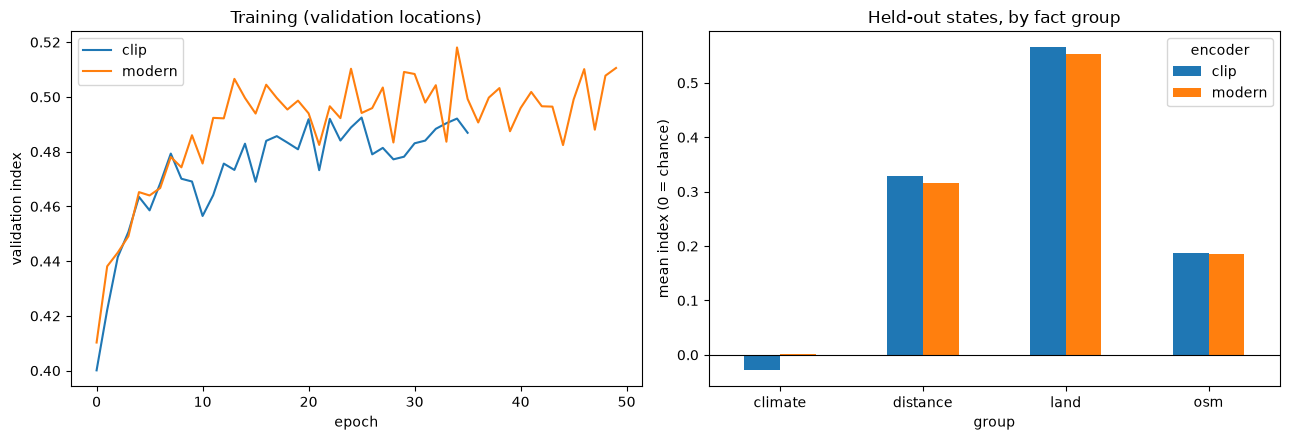

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for enc, h in HIST.items():
    axes[0].plot(h.epoch, h.val_index, label=enc)
axes[0].set(xlabel="epoch", ylabel="validation index", title="Training (validation locations)")
axes[0].legend()
g = CON[CON.heldout].groupby(["encoder", "group"])["index"].mean().unstack(0)
g.plot.bar(ax=axes[1], rot=0)
axes[1].axhline(0, color="k", lw=0.8)
axes[1].set(ylabel="mean index (0 = chance)", title="Held-out states, by fact group")
fig.tight_layout()
fig.savefig(FIG / "11_aether_us.png", dpi=120)
print(f"Run time {(time.time() - T_START) / 60:.1f} min")

## Best and worst concepts in the held-out states (CLIP encoder)

In [13]:
h = CON[(CON.encoder == "clip") & CON.heldout].dropna(subset=["index"])
pd.concat([h.nlargest(10, "index"), h.nsmallest(10, "index")])[["pool", "group", "text", "index"]].round(3)

,pool,group,text,index
499,minnesota,land,open water,0.906
745,georgia,land,cropland,0.900
502,minnesota,land,cropland,0.900
486,minnesota,land,corn fields,0.893
487,minnesota,land,soybean fields,0.863
734,georgia,land,cotton fields,0.847
521,minnesota,osm,water,0.833
729,georgia,land,corn fields,0.810
744,georgia,land,existing solar farms,0.809
735,georgia,land,other annual crops,0.799
